# My Notebook: Global Health Indicators
**Question:** Do countries that spend more on health care have longer lives and fewer infant deaths?

I follow the same flow as the original notebook (load → summarize → outliers → correlation → scatter), but with my own code and explanations.

**My improvements:**
1. **Missing-data check and cleaning:** check for missing or impossible values before analyzing.
2. **Outliers calculated with the IQR rule:** compute the outliers with numbers instead of guessing from the picture.
3. **A reusable function** to rank countries for any indicator (bar charts).
4. **Better scatter plot:** country labels and a log scale for spending, and I compare Pearson vs. Spearman correlation.
5. **New column:** "years of life per $1,000 spent" to see which countries are most efficient.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")   # one consistent style for all my plots

## 1. Load the data

In [ ]:
url = "https://raw.githubusercontent.com/duochen/data-science-bootcamp/refs/heads/main/Data/health_data.csv"
health = pd.read_csv(url)

# shorter column names make the code easier to read
health = health.rename(columns={
    "Life Expectancy": "life_exp",
    "Health Spending Per Capita": "spending",
    "Infant Mortality": "infant_mort",
})
print(health.shape)   # (rows, columns)
health

(10, 4)


,Country,life_exp,spending,infant_mort
0,Japan,84.5,4500,2.0
1,United States,78.9,10500,5.7
2,India,69.7,300,25.0
3,Nigeria,61.2,150,60.8
4,Norway,82.4,6500,2.5
5,Brazil,75.7,1200,12.4
6,Germany,81.1,5500,3.3
7,South Africa,64.1,500,27.5
8,China,76.9,1000,6.8
9,Bangladesh,72.3,250,24.2


## 2. Improvement #1: check for missing or bad data
The original notebook never checked whether the data was clean. I check for missing values and impossible values (negative numbers), and I write the code so it would still work if some values were missing.

In [ ]:
print("Missing values per column:")
print(health.isna().sum())

# impossible values: spending or mortality below 0, life expectancy outside 0-120
bad = health[(health["spending"] < 0) | (health["infant_mort"] < 0) |
             (~health["life_exp"].between(0, 120))]
print("\nRows with impossible values:", len(bad))

# if anything were missing, drop only rows missing the columns we need
clean = health.dropna(subset=["life_exp", "spending", "infant_mort"]).copy()
print("Rows kept:", len(clean), "of", len(health))

Missing values per column:
Country        0
life_exp       0
spending       0
infant_mort    0
dtype: int64

Rows with impossible values: 0
Rows kept: 10 of 10


**Result:** no missing or impossible values, so all 10 countries are kept. With only 10 countries, the conclusions below are a small sample, not the whole world.

## 3. Summary statistics

In [ ]:
summary = clean[["life_exp", "spending", "infant_mort"]].describe().round(1)
summary

,life_exp,spending,infant_mort
count,10.0,10.0,10.0
mean,74.7,3040.0,17.0
std,7.8,3550.4,18.3
min,61.2,150.0,2.0
25%,70.4,350.0,3.9
50%,76.3,1100.0,9.6
75%,80.6,5250.0,24.8
max,84.5,10500.0,60.8


Spending has a huge spread: the mean ($3,040) is almost 3× the median ($1,100), because a few rich countries pull the average up. This tells me spending is **skewed**, so a log scale will help later.

## 4. Improvement #2: find outliers with the IQR rule
Instead of only looking at the boxplot, I calculate the rule the boxplot uses: an outlier is below Q1 − 1.5×IQR or above Q3 + 1.5×IQR.

In [ ]:
def iqr_outliers(data, col):
    """Return the rows of `data` that are outliers in column `col`, plus the fences."""
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = data[(data[col] < low) | (data[col] > high)]
    return out, low, high

for col in ["life_exp", "spending", "infant_mort"]:
    out, low, high = iqr_outliers(clean, col)
    names = ", ".join(out["Country"]) if len(out) else "none"
    print(f"{col:12s} fences = [{low:8.1f}, {high:8.1f}]  outliers: {names}")

life_exp     fences = [    55.0,     95.8]  outliers: none
spending     fences = [ -7000.0,  12600.0]  outliers: none
infant_mort  fences = [   -27.5,     56.2]  outliers: Nigeria


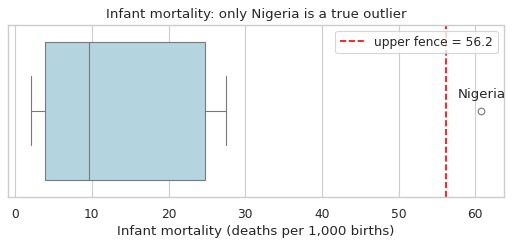

In [ ]:
out, low, high = iqr_outliers(clean, "infant_mort")

fig, ax = plt.subplots(figsize=(8, 2.8))
sns.boxplot(x=clean["infant_mort"], ax=ax, color="lightblue")
ax.axvline(high, color="red", linestyle="--", label=f"upper fence = {high:.1f}")
for _, row in out.iterrows():                     # label each outlier with its country name
    ax.annotate(row["Country"], (row["infant_mort"], 0), xytext=(0, 12),
                textcoords="offset points", ha="center")
ax.set_xlabel("Infant mortality (deaths per 1,000 births)")
ax.set_title("Infant mortality: only Nigeria is a true outlier")
ax.legend()
plt.show()

The original notes guessed Nigeria **and** South Africa would be outliers. The calculation shows only **Nigeria** (60.8) is past the fence (≈56.2). South Africa (27.5) is high but within the normal range for this group.

## 5. Improvement #3: a function to rank countries
I wrote one function that ranks the countries for any column, so I don't repeat the same plotting code three times.

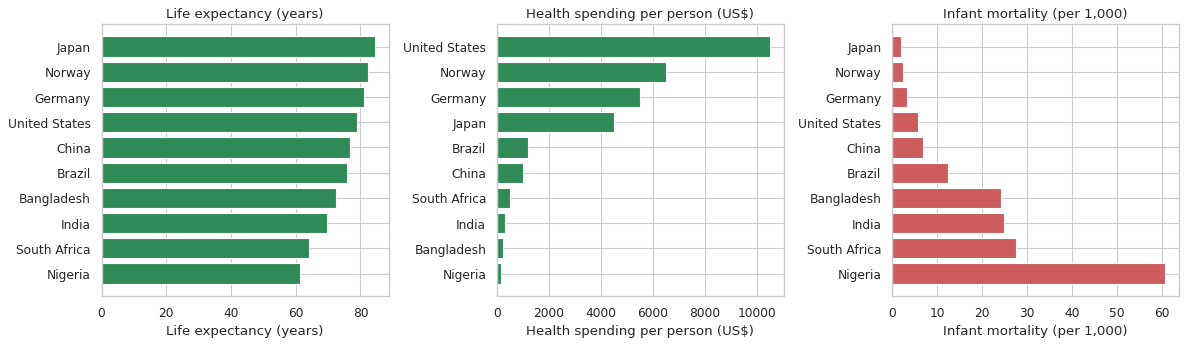

In [ ]:
def rank_countries(data, col, label, ax, high_is_good=True):
    """Horizontal bar chart of `col`, sorted so the best country is on top."""
    ordered = data.sort_values(col, ascending=high_is_good)
    colors = ["seagreen" if high_is_good else "indianred"] * len(ordered)
    ax.barh(ordered["Country"], ordered[col], color=colors)
    ax.set_xlabel(label)
    ax.set_title(label)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
rank_countries(clean, "life_exp", "Life expectancy (years)", axes[0])
rank_countries(clean, "spending", "Health spending per person (US$)", axes[1])
rank_countries(clean, "infant_mort", "Infant mortality (per 1,000)", axes[2], high_is_good=False)
plt.tight_layout()
plt.show()

Comparing the three charts: the United States is #1 in spending but only #4 in life expectancy. Japan spends less than half as much and lives the longest.

## 6. Correlation

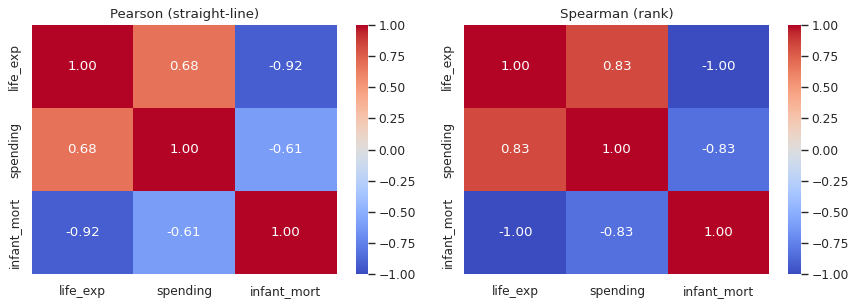

In [ ]:
cols = ["life_exp", "spending", "infant_mort"]
pearson = clean[cols].corr(method="pearson")
spearman = clean[cols].corr(method="spearman")   # uses ranks, so it handles curved relationships

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, m, name in zip(axes, [pearson, spearman], ["Pearson (straight-line)", "Spearman (rank)"]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Pearson** (what the original used) says spending vs. life expectancy ≈ **0.68**. **Spearman** gives ≈ **0.83**. Spearman only cares about the order, so the much higher number means the relationship is strong but **curved, not a straight line**. Infant mortality vs. life expectancy is strongly negative (−0.92), and Spearman gives −1.00: the order of the countries is exactly reversed.

## 7. Improvement #4: a better scatter plot
The original scatter had no country names, and the US squeezed everyone else into the left side. I add labels and put spending on a **log scale**.

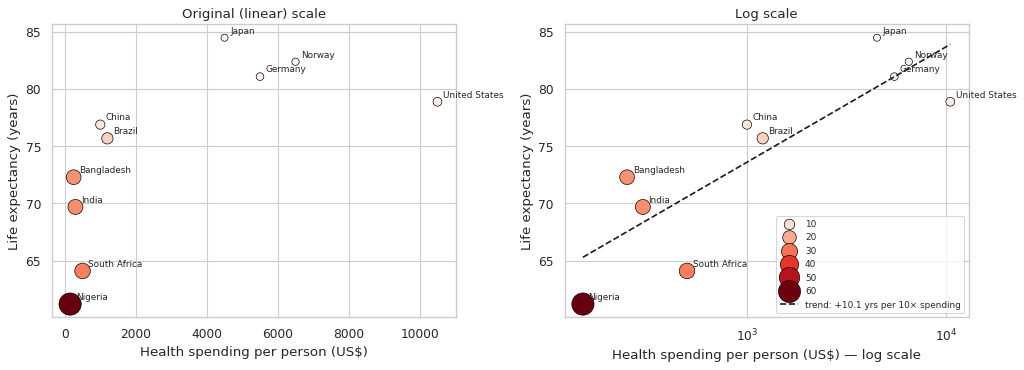

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for ax, log in zip(axes, [False, True]):
    sns.scatterplot(data=clean, x="spending", y="life_exp", size="infant_mort",
                    sizes=(40, 400), hue="infant_mort", palette="Reds", edgecolor="black", linewidth=0.6, ax=ax, legend=log)
    for _, r in clean.iterrows():
        ax.annotate(r["Country"], (r["spending"], r["life_exp"]), xytext=(5, 4),
                    textcoords="offset points", fontsize=8)
    if log:
        ax.set_xscale("log")
        # straight-line fit on log(spending) to show the trend
        b, a = np.polyfit(np.log10(clean["spending"]), clean["life_exp"], 1)
        xs = np.logspace(np.log10(clean["spending"].min()), np.log10(clean["spending"].max()), 50)
        ax.plot(xs, a + b * np.log10(xs), "k--", label=f"trend: +{b:.1f} yrs per 10× spending")
        ax.legend(fontsize=8, loc="lower right")
    ax.set_xlabel("Health spending per person (US$)" + (" — log scale" if log else ""))
    ax.set_ylabel("Life expectancy (years)")
    ax.set_title("Log scale" if log else "Original (linear) scale")

plt.tight_layout()
plt.show()

On the log scale the points are much closer to a straight line: each **10× increase** in spending goes with roughly **+10 years** of life expectancy. Bigger, redder dots = higher infant mortality, so they cluster at low spending and low life expectancy.

## 8. Improvement #5: years of life per $1,000 spent

In [ ]:
clean["years_per_1000"] = clean["life_exp"] / (clean["spending"] / 1000)
clean.sort_values("years_per_1000", ascending=False)[["Country", "spending", "life_exp", "years_per_1000"]].round(1)

,Country,spending,life_exp,years_per_1000
3,Nigeria,150,61.2,408.0
9,Bangladesh,250,72.3,289.2
2,India,300,69.7,232.3
7,South Africa,500,64.1,128.2
8,China,1000,76.9,76.9
5,Brazil,1200,75.7,63.1
0,Japan,4500,84.5,18.8
6,Germany,5500,81.1,14.7
4,Norway,6500,82.4,12.7
1,United States,10500,78.9,7.5


This number is highest for low-spending countries (Nigeria, Bangladesh), because the first dollars spent on health matter the most. It is lowest for the United States. It confirms the scatter plot: there are **diminishing returns** to health spending.

## 9. Summary
| Analysis | What I found |
|---|---|
| Data check | No missing or impossible values; only 10 countries |
| IQR outliers | Only Nigeria is an infant-mortality outlier (not South Africa) |
| Rankings | US spends the most, Japan lives the longest |
| Correlation | Spending ↔ life expectancy: Pearson 0.68 vs. Spearman 0.83 → strong but curved |
| Log scatter | ~+10 years of life per 10× more spending |
| Efficiency | Diminishing returns: the US gets the fewest years per $1,000 |

## 10. Reflection
*(Draft — rewrite this in your own words before submitting.)*

The notebook was about global health. It used data on 10 countries to compare life expectancy, health spending per person, and infant mortality, using a boxplot, a correlation heatmap and a scatter plot. In my version I first checked the data for missing or impossible values, and then calculated the outliers with the IQR rule instead of guessing from the picture. That showed only Nigeria is an outlier, not Nigeria and South Africa like the original notes said. I also wrote a function to rank the countries with bar charts, added country labels and a log scale to the scatter plot, and compared Pearson with Spearman correlation. I learned that a correlation number can be misleading: spending and life expectancy have a strong relationship, but it is curved, so Pearson makes it look weaker than it is. I also learned that more money does not always mean better health, because the United States spends the most but Japan lives the longest. Finally, I learned that only 10 countries is a small sample, so these results are a starting point, not a final answer.